# 05 - Integrated EDA (BijliCast)

**CT-378 Phase 2 - integrated EDA step**

Studies relationships between electricity usage and (a) weather and (b) static
household features on the integrated table. Produces 4 plots (total EDA plots > 5).

In [1]:
import re
from pathlib import Path

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns

sns.set_theme(style="whitegrid", context="notebook")
plt.rcParams["figure.dpi"] = 110

ROOT = Path.cwd()
while not (ROOT / "datasets").exists() and ROOT != ROOT.parent:
    ROOT = ROOT.parent
PROC = ROOT / "data" / "processed"
FIG = ROOT / "reports" / "figures"
FIG.mkdir(parents=True, exist_ok=True)
print("Repo root:", ROOT)
df = pd.read_parquet(PROC / "merged_dataset.parquet")
df["datetime"] = pd.to_datetime(df["datetime"])
wx = ["temperature","humidity","dew","precipitation","wind_speed","wind_direction","pressure","solar_radiation"]
print("merged_dataset:", df.shape)

Repo root: D:\BijliCast


merged_dataset: (515786, 31)


### Plot 12 - Mean usage by temperature bin, per city

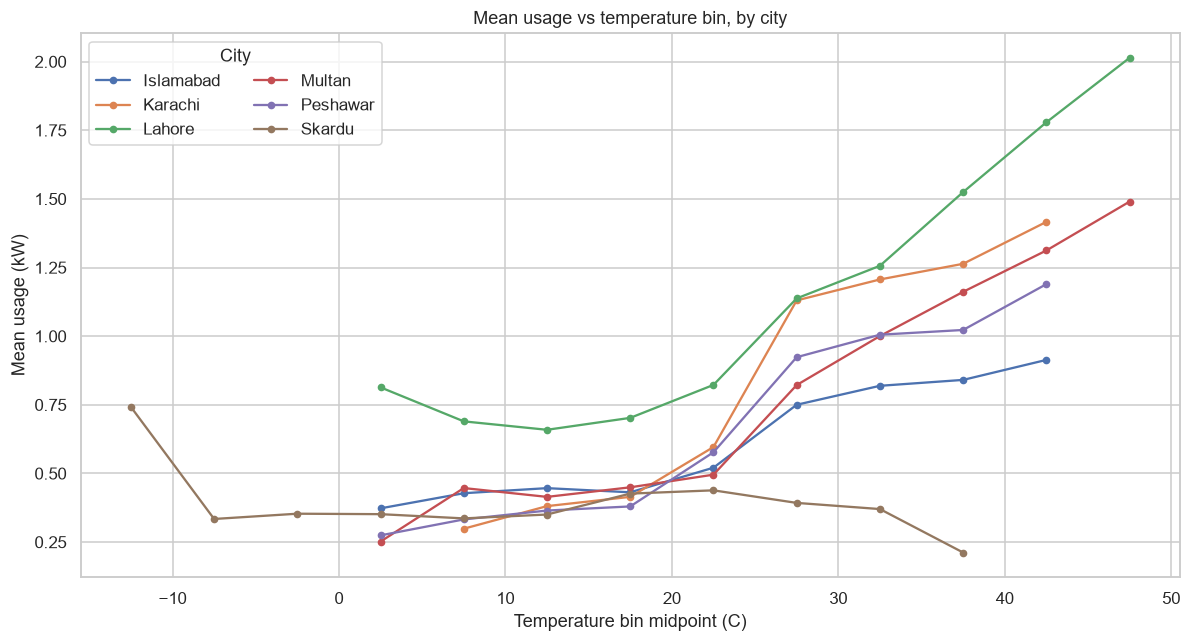

In [2]:
d = df.dropna(subset=["temperature", "usage_kw"]).copy()
d["temp_bin"] = pd.cut(d["temperature"], bins=range(-15, 51, 5))
piv = d.groupby(["city", "temp_bin"], observed=True)["usage_kw"].mean().unstack(0)
# bin midpoints for the x-axis
mid = [iv.mid for iv in piv.index]
plt.figure(figsize=(11, 6))
for c in piv.columns:
    plt.plot(mid, piv[c].values, marker="o", ms=4, label=c)
plt.title("Mean usage vs temperature bin, by city")
plt.xlabel("Temperature bin midpoint (C)")
plt.ylabel("Mean usage (kW)")
plt.legend(title="City", ncol=2)
plt.tight_layout()
plt.savefig(FIG / "05_usage_by_temp_bin.png", dpi=220, bbox_inches="tight")
plt.show()

### Plot 13 - Weather-usage correlation per city

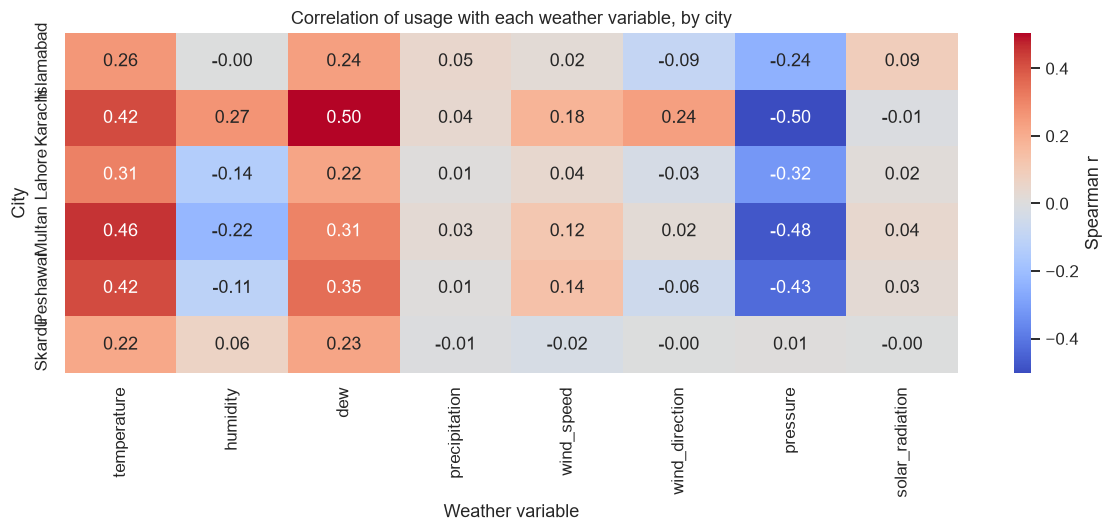

In [3]:
rows = []
for c in sorted(df["city"].unique()):
    d = df[df["city"] == c][["usage_kw"] + wx].dropna()
    if len(d) < 10:
        continue
    r = d.corr(method="spearman").loc["usage_kw", wx]
    r.name = c
    rows.append(r)
corr_city = pd.DataFrame(rows)
plt.figure(figsize=(11, 5))
sns.heatmap(corr_city, annot=True, fmt=".2f", cmap="coolwarm", center=0, cbar_kws={"label": "Spearman r"})
plt.title("Correlation of usage with each weather variable, by city")
plt.xlabel("Weather variable")
plt.ylabel("City")
plt.tight_layout()
plt.savefig(FIG / "05_corr_usage_weather_by_city.png", dpi=220, bbox_inches="tight")
plt.show()

### Plot 14 - Air conditioners vs mean household usage

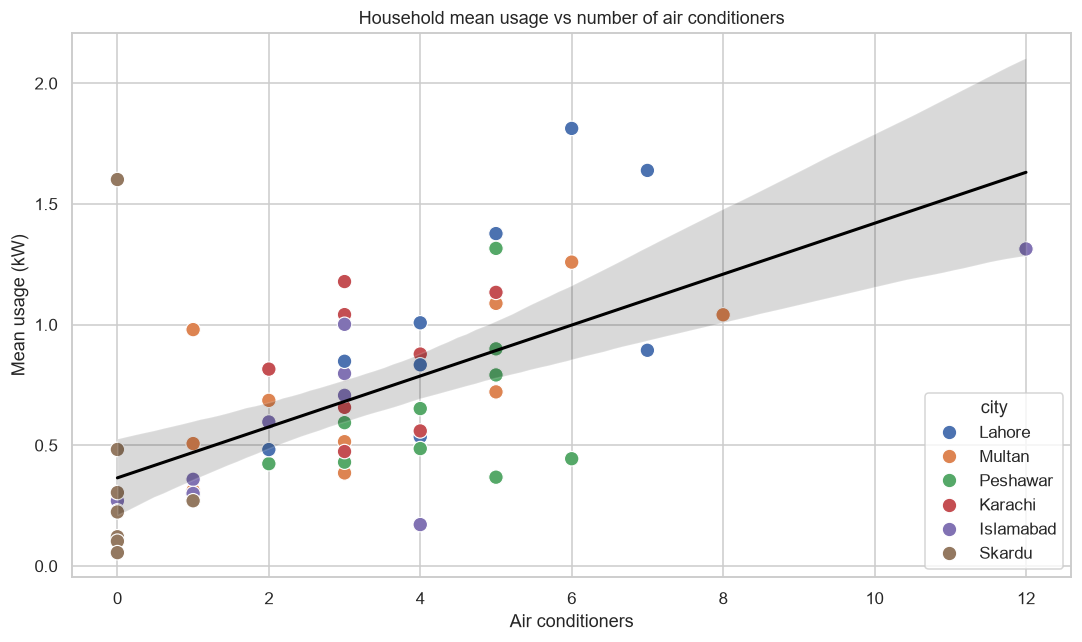

Correlation(ACs, mean usage) = 0.61


In [4]:
h = (df.groupby(["house_id", "city"])
       .agg(ac=("Air Conditioners", "first"), mean_usage=("usage_kw", "mean"))
       .reset_index().dropna())
plt.figure(figsize=(10, 6))
sns.scatterplot(data=h, x="ac", y="mean_usage", hue="city", s=90)
sns.regplot(data=h, x="ac", y="mean_usage", scatter=False, color="black", line_kws={"lw": 2})
plt.title("Household mean usage vs number of air conditioners")
plt.xlabel("Air conditioners")
plt.ylabel("Mean usage (kW)")
plt.tight_layout()
plt.savefig(FIG / "05_acs_vs_mean_usage.png", dpi=220, bbox_inches="tight")
plt.show()
print("Correlation(ACs, mean usage) =", round(h[["ac", "mean_usage"]].corr().iloc[0, 1], 3))

### Plot 15 - Weekday vs weekend load profile

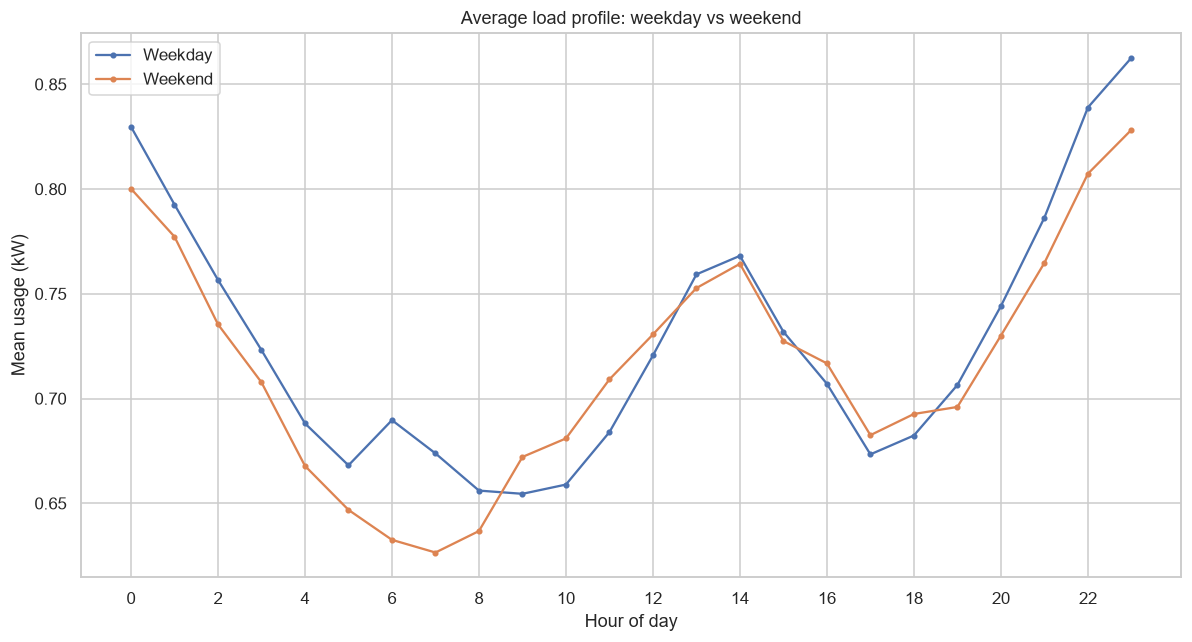

In [5]:
df["hour"] = df["datetime"].dt.hour
df["is_weekend"] = df["datetime"].dt.dayofweek >= 5
prof = df.groupby(["is_weekend", "hour"])["usage_kw"].mean().unstack(0)
plt.figure(figsize=(11, 6))
plt.plot(prof.index, prof[False], marker="o", ms=3, label="Weekday")
plt.plot(prof.index, prof[True], marker="o", ms=3, label="Weekend")
plt.title("Average load profile: weekday vs weekend")
plt.xlabel("Hour of day")
plt.ylabel("Mean usage (kW)")
plt.xticks(range(0, 24, 2))
plt.legend()
plt.tight_layout()
plt.savefig(FIG / "05_weekday_vs_weekend.png", dpi=220, bbox_inches="tight")
plt.show()

## Findings - Notebook 05

- Usage rises with temperature in warmer cities but flattens/changes in cold Skardu.
- Correlation-by-city heatmaps show which weather variables matter per climate.
- **Air-conditioner count** is positively associated with a household's mean usage - a useful static predictor.
- Weekday vs weekend profiles differ, supporting calendar features (`is_weekend`, `day_of_week`).
- Phase 2 now exceeds the CT-378 EDA requirement with **15 saved plots**.